In [66]:
import  pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import TensorDataset, DataLoader

In [67]:

# 4. 搭建模型
digit_model = nn.Sequential(
    # shape=[N,6,28,28] 5 1 2  保持不变
    nn.Conv2d(1, 6, kernel_size=5, padding=2,stride=1),
    nn.Sigmoid(),
    # shape=[N,6,14,14] 见一面砍一半
    nn.AvgPool2d(2, 2),
    #shape [N,16,10,10] 10=(H+2P-K)/S+1= (14-5)/1+1=9+1=10
    nn.Conv2d(6, 16, 5),
    nn.Sigmoid(),
    #shape [N,16,5,5]
    nn.AvgPool2d(2, 2),
    #SHAPE [N,400]
    nn.Flatten(),
    nn.Linear(16 * 5 * 5, 120),
    nn.Sigmoid(),
    nn.Linear(120, 84),
    nn.Sigmoid(),
    nn.Linear(84, 10),
)
tensor=torch.randn((1,1,28,28))
output=digit_model(tensor)
print(output)


tensor([[ 0.0086, -0.1438, -0.0671, -0.5031,  0.4551,  0.1572,  0.7505, -0.1700,
          0.1448,  0.0575]], grad_fn=<AddmmBackward0>)


In [68]:

# 加载训练样本
train_sample:pd.DataFrame=pd.read_csv("../data/fashion-mnist_train.csv")
# 加载测试样本
test_sample:pd.DataFrame=pd.read_csv("../data/fashion-mnist_test.csv")

# 拆分训练特征
train_feature=train_sample.iloc[:,1:]
# 拆分测试特征
test_feature=test_sample.iloc[:,1:]

# 拆分训练特征
train_label=train_sample.iloc[:,0]
# 拆分测试特征
test_label=test_sample.iloc[:,0]

### 规一化

In [69]:
# scaler=MinMaxScaler()
# train_feature=scaler.fit_transform(train_feature)
# test_feature=scaler.transform(test_feature)
# train_feature_tensor=torch.tensor(train_feature)


### 转成tensor

In [70]:
train_feature_tensor=torch.tensor(train_feature.values,dtype=torch.float)
test_feature_tensor=torch.tensor(test_feature.values,dtype=torch.float)

train_label_tensor=torch.tensor(train_label)
test_label_tensor=torch.tensor(test_label)
# 调整形状
train_feature_tensor=train_feature_tensor.reshape(-1,1,28,28)
test_feature_tensor=test_feature_tensor.reshape(-1,1,28,28)

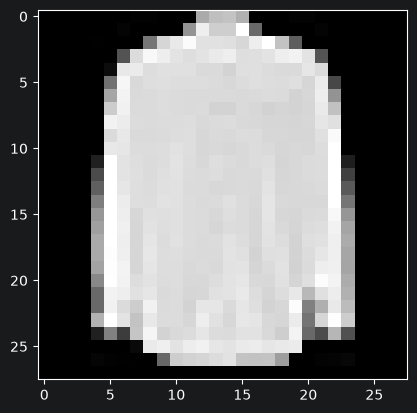

In [71]:
plt.imshow(train_feature_tensor[232].squeeze(),cmap='gray')

In [72]:
# 4. 搭建模型
digit_model = nn.Sequential(
    # shape=[N,6,28,28] 5 1 2  保持不变
    nn.Conv2d(1, 6, kernel_size=5, padding=2,stride=1),
    nn.Sigmoid(),
    # shape=[N,6,14,14] 见一面砍一半
    nn.AvgPool2d(2, 2),
    #shape [N,16,10,10] 10=(H+2P-K)/S+1= (14-5)/1+1=9+1=10
    nn.Conv2d(6, 16, 5),
    nn.Sigmoid(),
    #shape [N,16,5,5]
    nn.AvgPool2d(2, 2),
    #SHAPE [N,400]
    nn.Flatten(),
    nn.Linear(16 * 5 * 5, 120),
    nn.Sigmoid(),
    nn.Linear(120, 84),
    nn.Sigmoid(),
    nn.Linear(84, 10),
)
tensor=torch.randn((1,1,28,28))
output=digit_model(tensor)
print(output.grad_fn)


In [73]:
epochs=10
lr=0.1
batch_size=256

In [74]:
train_data_set=TensorDataset(train_feature_tensor,train_label_tensor)

test_date_set=TensorDataset(test_feature_tensor,test_label_tensor)

train_data_loader=DataLoader(train_data_set,batch_size=batch_size,shuffle=True)

test_data_loader=DataLoader(test_date_set,batch_size=batch_size)

- input (Tensor) : Predicted unnormalized logits;
- target (Tensor) : Ground truth class indices or class probabilities;

In [75]:
loss_fn = nn.CrossEntropyLoss()
optimizer=Adam(digit_model.parameters(),lr=lr)

In [76]:

for epoch in range(epochs):
    this_loss=0
    total_loss=0
    this_acc=0
    acc_total=0
    digit_model.train()
    for features,labels in train_data_loader:
        print(f"features requires_grad: {features.requires_grad}")
        output = digit_model(features)
        print(output.requires_grad)
        loss = loss_fn(output, labels)
        loss.backward()
        # total_loss += loss.item()
        # preds = preds.argmax(dim=-1)
        # acc = preds.eq(labels).sum().item()
        optimizer.step()
        optimizer.zero_grad()

    this_loss=total_loss/len(train_data_loader)
    this_acc=acc_total/len(train_sample)

    digit_model.eval()
    this_test_loss=0
    total_test_loss=0
    this_test_acc=0
    acc_test_total=0
    with torch.no_grad():
        for test_features,test_labels in test_data_loader:
            test_preds = digit_model(test_features)
            test_loss = loss_fn(test_preds,test_labels)
            total_test_loss += test_loss.item()
            test_pred_labels = test_preds.argmax(dim=-1)
            acc_test_total=test_pred_labels.eq(test_labels).sum().item()

        this_test_loss=total_test_loss/len(test_data_loader)
        this_test_acc=acc_test_total/len(test_sample)



features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_grad: False
True
features requires_gr

KeyboardInterrupt: 